# BÀI 4. XÂY DỰNG MÔ HÌNH MLP CHO DỮ LIỆU ẢNH
## Trọng tâm: Workflow Deep Learning hoàn chỉnh

**Mục tiêu bài thực hành**

1. Hiểu dữ liệu ảnh được biểu diễn dưới dạng tensor như thế nào.
2. Tách dữ liệu thành **training / validation / test** đúng vai trò.
3. Tiền xử lý dữ liệu phù hợp cho mạng nơ-ron.
4. Xây dựng một mô hình **Multi-Layer Perceptron (MLP)** bằng TensorFlow/Keras.
5. Hiểu quy trình **compile → train → validate → evaluate → predict**.
6. Theo dõi quá trình học qua **loss curve** và **accuracy curve**.
7. Nhận biết dấu hiệu **underfitting / overfitting**.
8. Sử dụng callback như **EarlyStopping** và **ModelCheckpoint**.
9. Đánh giá mô hình bằng accuracy, confusion matrix và classification report.
10. Thực hiện inference trên ảnh mới và lưu/khôi phục mô hình.

---

### Bộ dữ liệu sử dụng: Fashion-MNIST

Fashion-MNIST gồm ảnh xám kích thước **28×28**, thuộc **10 lớp** trang phục.

Bộ dữ liệu này phù hợp để học MLP vì:
- dữ liệu đủ nhỏ để huấn luyện nhanh trên Colab;
- khó hơn MNIST chữ số;
- ảnh có cấu trúc rõ ràng;
- MLP có thể xử lý trực tiếp sau khi làm phẳng ảnh thành vector.

> **Lưu ý:** MLP không khai thác tốt cấu trúc không gian của ảnh như CNN. Trong bài này, MLP được dùng để tập trung vào **workflow của Deep Learning**. CNN sẽ là bước tiếp theo tự nhiên.

## 1. Chuẩn bị môi trường và thư viện

Trong Deep Learning, chúng ta thường cần:

- thư viện xử lý số liệu;
- thư viện trực quan hóa;
- framework Deep Learning;
- công cụ đánh giá mô hình.

In [242]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


###  đọc kết quả

- `TensorFlow version` cho biết phiên bản framework đang sử dụng.
- `GPU available` cho biết Colab có nhận GPU hay không.
- Với Fashion-MNIST và MLP nhỏ, CPU vẫn có thể chạy được; tuy nhiên GPU giúp huấn luyện nhanh hơn.

### Phân tích thực tế

Trong các dự án Deep Learning lớn, môi trường tính toán ảnh hưởng trực tiếp đến thời gian huấn luyện. Vì vậy, kiểm tra GPU là một bước quen thuộc trước khi bắt đầu.

## 2. Thiết lập random seed để tăng khả năng tái lập kết quả

Deep Learning có nhiều yếu tố ngẫu nhiên:
- khởi tạo trọng số;
- thứ tự mini-batch;
- một số phép toán trên GPU.

Đặt seed giúp các lần chạy cho kết quả gần nhau hơn.

In [243]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed =", SEED)

Random seed = 42


### đọc kết quả

Nếu notebook được chạy lại với cùng seed, quá trình huấn luyện thường cho kết quả gần tương tự.

### Phân tích thực tế

Không nên hiểu seed là đảm bảo 100% mọi lần chạy giống hệt nhau trên mọi phần cứng. Tuy nhiên, đây là bước quan trọng để thí nghiệm có tính **reproducibility**.

## 3. Tải dữ liệu Fashion-MNIST

Keras cung cấp sẵn Fashion-MNIST nên không cần tải file thủ công.

Dữ liệu gốc đã được chia thành:
- **60,000 ảnh training**
- **10,000 ảnh test**

Sau đó ta sẽ tiếp tục tách một phần training thành validation.

In [244]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Kiểu dữ liệu ảnh:", X_train_full.dtype)
print("Khoảng giá trị pixel:", X_train_full.min(), "->", X_train_full.max())

X_train_full: (60000, 28, 28)
y_train_full: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)
Kiểu dữ liệu ảnh: uint8
Khoảng giá trị pixel: 0 -> 255


### đọc kết quả

- `(60000, 28, 28)` nghĩa là có 60,000 ảnh, mỗi ảnh kích thước 28×28.
- Nhãn có dạng vector 1 chiều, mỗi phần tử là một số nguyên từ 0 đến 9.
- Pixel ảnh gốc nằm trong khoảng **0–255**.

### Phân tích thực tế

Ảnh không phải là một bảng feature được thiết kế sẵn như bài hồi quy hay classification trước. Mỗi pixel chính là một giá trị đầu vào. Đây là điểm chuyển quan trọng từ dữ liệu bảng sang dữ liệu ảnh.

## 4. Khám phá nhanh dữ liệu ảnh

Ở bài này chúng ta **không tập trung vào EDA sâu** như với dữ liệu bảng.  
Mục đích của bước này chỉ là:

1. hiểu ảnh trông như thế nào;
2. kiểm tra nhãn;
3. kiểm tra phân bố lớp;
4. xác nhận dữ liệu hợp lý trước khi huấn luyện.

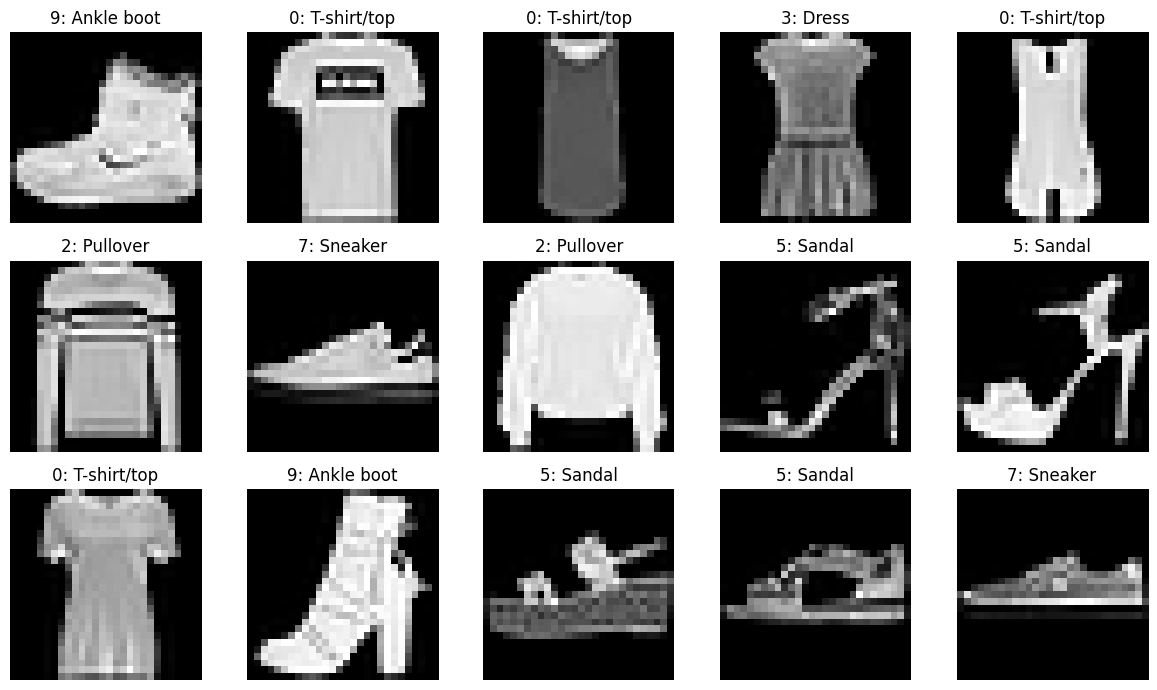

In [245]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_full[i], cmap="gray")
    ax.set_title(f"{y_train_full[i]}: {class_names[y_train_full[i]]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

###  đọc kết quả

Mỗi ảnh được hiển thị cùng:
- mã nhãn;
- tên lớp tương ứng.

### Phân tích thực tế

Ảnh Fashion-MNIST khá nhỏ và không chứa màu. Một số lớp có hình dạng gần nhau như:
- `T-shirt/top`;
- `Shirt`;
- `Pullover`;
- `Coat`.

Do đó đây là bài toán khó hơn nhận dạng chữ số MNIST.

In [246]:
unique, counts = np.unique(y_train_full, return_counts=True)

class_distribution = pd.DataFrame({
    "class_id": unique,
    "class_name": [class_names[i] for i in unique],
    "count": counts
})

display(class_distribution)

,class_id,class_name,count
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


### đọc kết quả

Bảng cho biết số mẫu của từng lớp.

### Phân tích thực tế

Fashion-MNIST được xây dựng khá cân bằng, nên ở bài này **không cần sampling để xử lý class imbalance** như bài 3. Điều đó giúp ta tập trung vào quy trình huấn luyện Deep Learning.

## 5. Tách Training / Validation / Test

Trong Deep Learning, ba tập dữ liệu có vai trò khác nhau:

- **Training set**: dùng để cập nhật trọng số mô hình bằng gradient descent.
- **Validation set**: dùng để theo dõi khả năng tổng quát hóa trong quá trình huấn luyện và lựa chọn epoch/hyperparameter.
- **Test set**: chỉ dùng ở cuối để đánh giá mô hình đã hoàn thiện.

> Không nên dùng test set để điều chỉnh mô hình.

In [247]:
VAL_SIZE = 10_000

X_val = X_train_full[-VAL_SIZE:]
y_val = y_train_full[-VAL_SIZE:]

X_train = X_train_full[:-VAL_SIZE]
y_train = y_train_full[:-VAL_SIZE]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (50000, 28, 28) (50000,)
Validation: (10000, 28, 28) (10000,)
Test: (10000, 28, 28) (10000,)


### đọc kết quả

Ta thu được:
- 50,000 mẫu training;
- 10,000 mẫu validation;
- 10,000 mẫu test.

### Phân tích thực tế

Validation set đóng vai trò rất quan trọng trong Deep Learning vì một mô hình có thể tiếp tục giảm training loss nhưng bắt đầu tăng validation loss. Đó là dấu hiệu overfitting.

## 6. Chuẩn hóa dữ liệu ảnh

Mỗi pixel ban đầu nằm trong khoảng `[0, 255]`.

Ta chuyển sang `float32` và chia cho 255 để đưa dữ liệu về `[0, 1]`.

Việc chuẩn hóa giúp:
- gradient ổn định hơn;
- tối ưu dễ hơn;
- các layer nhận dữ liệu ở thang đo phù hợp.

In [248]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training min/max:", X_train.min(), X_train.max())
print("Validation min/max:", X_val.min(), X_val.max())
print("Test min/max:", X_test.min(), X_test.max())

Training min/max: 0.0 1.0
Validation min/max: 0.0 1.0
Test min/max: 0.0 1.0


### đọc kết quả

Sau chuẩn hóa:
- giá trị nhỏ nhất ≈ 0;
- giá trị lớn nhất ≈ 1.

### Phân tích thực tế

Trong Deep Learning, scale dữ liệu thường ảnh hưởng mạnh đến tốc độ hội tụ. Với ảnh xám, chia cho 255 là cách chuẩn hóa đơn giản và hiệu quả.

## 7. Tạo input pipeline bằng `tf.data`

Deep Learning thường huấn luyện bằng **mini-batch**, không đưa toàn bộ dữ liệu vào mô hình cùng lúc.

`tf.data.Dataset` giúp:
- tạo batch;
- shuffle dữ liệu;
- prefetch dữ liệu;
- xây dựng pipeline có thể mở rộng cho dữ liệu lớn.

In [249]:
BATCH_SIZE = 64

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

for images, labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", labels.shape)

Batch images shape: (64, 28, 28)
Batch labels shape: (64,)


### đọc kết quả

Một batch có dạng:

- ảnh: `(batch_size, 28, 28)`
- nhãn: `(batch_size,)`

### Phân tích thực tế

Mini-batch là đơn vị cơ bản của quá trình huấn luyện Deep Learning. Mỗi batch đi qua:
1. forward pass;
2. tính loss;
3. backpropagation;
4. cập nhật trọng số.

Sau khi đi hết mọi batch, ta hoàn thành **1 epoch**.

## 8. Xây dựng mô hình MLP

Ảnh có dạng ma trận `28 × 28`.  
MLP yêu cầu vector đầu vào, nên trước hết cần **Flatten** ảnh:

\[
28 \times 28 = 784
\]

Sau đó dữ liệu đi qua các Dense layer:

\[
784 \rightarrow 256 \rightarrow 128 \rightarrow 10
\]

Layer cuối có 10 neuron, tương ứng 10 lớp.

In [250]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

###  đọc kết quả

`model.summary()` cho biết:
- tên từng layer;
- kích thước output;
- số parameter cần học.

Dense layer có số tham số:

`input_size × output_size + bias`

### Phân tích thực tế

Số parameter của MLP có thể khá lớn dù ảnh chỉ 28×28. Nguyên nhân là mỗi neuron Dense kết nối với toàn bộ đầu vào. Đây cũng là một lý do CNN thường hiệu quả hơn cho dữ liệu ảnh.

## 9. Compile mô hình

Trước khi train, cần xác định ba thành phần:

1. **Optimizer** – cách cập nhật trọng số.
2. **Loss function** – hàm mục tiêu cần tối thiểu hóa.
3. **Metric** – chỉ số theo dõi hiệu năng.

Ở đây sử dụng:

- Optimizer: `Adam`
- Loss: `SparseCategoricalCrossentropy`
- Metric: `accuracy`

Vì nhãn được lưu dưới dạng số nguyên `0...9`, ta dùng **sparse categorical cross-entropy**.

In [251]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


###đọc kết quả

Nếu cell chạy không lỗi, mô hình đã sẵn sàng để huấn luyện.

### Phân tích thực tế

`compile()` không huấn luyện mô hình. Nó chỉ thiết lập quy tắc huấn luyện. Việc cập nhật trọng số chỉ xảy ra khi gọi `fit()`.

## 10. Callback trong Deep Learning

Huấn luyện mạng nơ-ron có thể kéo dài nhiều epoch. Callback giúp kiểm soát quá trình này.

Ta sử dụng:

### EarlyStopping
Dừng huấn luyện khi validation loss không còn cải thiện.

### ModelCheckpoint
Lưu lại mô hình có validation loss tốt nhất.

Đây là workflow phổ biến trong thực tế để tránh giữ mô hình ở epoch cuối nếu epoch đó đã overfit.

In [252]:
checkpoint_path = "best_mlp_fashion.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks ready.")

Callbacks ready.


## 11. Huấn luyện mô hình

Trong mỗi epoch:

1. mô hình chạy qua toàn bộ training set;
2. optimizer cập nhật trọng số theo từng mini-batch;
3. cuối epoch, mô hình được đánh giá trên validation set.

Ta theo dõi đồng thời:
- `loss`;
- `accuracy`;
- `val_loss`;
- `val_accuracy`.

In [253]:
EPOCHS = 40

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8202 - loss: 0.5029 - val_accuracy: 0.8474 - val_loss: 0.4315
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8637 - loss: 0.3711 - val_accuracy: 0.8702 - val_loss: 0.3584
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8786 - loss: 0.3289 - val_accuracy: 0.8714 - val_loss: 0.3493
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8871 - loss: 0.3049 - val_accuracy: 0.8758 - val_loss: 0.3405
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8945 - loss: 0.2841 - val_accuracy: 0.8860 - val_loss: 0.3219
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9003 - loss: 0.2711 - val_accuracy: 0.8822 - val_loss: 0.3220
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9021 - loss: 0.2609 - val_accuracy: 0.8870 - val_loss: 0.3113
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9081 - loss: 0.2463 - val_accuracy: 0.

### đọc kết quả

Mỗi dòng epoch thường có:

- `loss`: training loss;
- `accuracy`: training accuracy;
- `val_loss`: validation loss;
- `val_accuracy`: validation accuracy.

### Phân tích thực tế

Một quá trình học tốt thường có:
- training loss giảm;
- validation loss cũng giảm trong giai đoạn đầu;
- accuracy tăng dần.

Nếu training loss tiếp tục giảm nhưng validation loss tăng, mô hình đang **overfitting**.

## 12. Trực quan hóa learning curves

Learning curve là công cụ quan trọng để đọc quá trình huấn luyện Deep Learning.

Ta sẽ vẽ:
- Loss theo epoch;
- Accuracy theo epoch.

In [254]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

,accuracy,loss,val_accuracy,val_loss
7,0.90812,0.246272,0.8850,0.321598
8,0.91198,0.234133,0.8916,0.306010
9,0.91632,0.226371,0.8913,0.313545
10,0.91650,0.217995,0.8881,0.331573
11,0.92028,0.210881,0.8911,0.316336


### đọc kết quả

Mỗi dòng tương ứng một epoch.  
Bảng này là dữ liệu nguồn để phân tích quá trình học.

### Phân tích thực tế

Không nên chỉ nhìn accuracy cuối cùng. Lịch sử training giúp ta biết:
- mô hình học nhanh hay chậm;
- bắt đầu overfit ở epoch nào;
- callback có dừng hợp lý không.

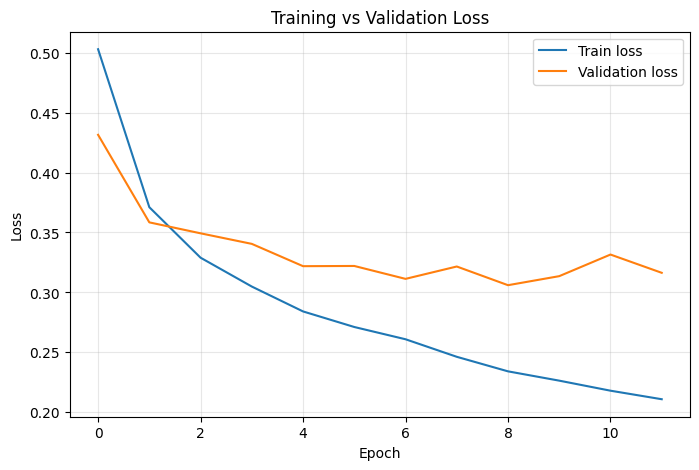

In [255]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

###  đọc kết quả

- Đường train loss cho biết mức lỗi trên training set.
- Đường validation loss cho biết khả năng tổng quát hóa trên dữ liệu chưa dùng để cập nhật trọng số.

### Phân tích thực tế

- Hai đường cùng giảm: mô hình đang học tốt.
- Train loss giảm nhưng val loss tăng: overfitting.
- Cả hai đều cao và gần nhau: có thể underfitting.

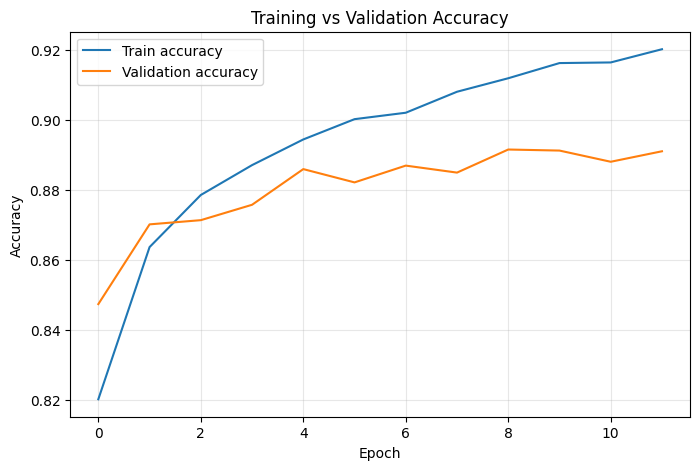

In [256]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

###  đọc kết quả

So sánh khoảng cách giữa training accuracy và validation accuracy.

### Phân tích thực tế

Khoảng cách nhỏ thường cho thấy mô hình tổng quát hóa tương đối tốt. Nếu training accuracy cao hơn validation accuracy quá nhiều, mô hình có thể đang ghi nhớ training set.

## 13. Đánh giá cuối cùng trên Test Set

Sau khi quá trình train và lựa chọn mô hình hoàn tất, ta mới đánh giá trên test set.

Test set đóng vai trò như dữ liệu hoàn toàn mới.

In [257]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")

Test loss     : 0.3303
Test accuracy : 0.8830


###  đọc kết quả

`Test accuracy` là tỷ lệ dự đoán đúng trên dữ liệu test.

### Phân tích thực tế

Nếu validation accuracy và test accuracy gần nhau, kết quả validation có khả năng phản ánh tốt khả năng tổng quát hóa. Nếu test accuracy giảm mạnh, quy trình tuning có thể đã phụ thuộc quá nhiều vào validation set.

## 14. Dự đoán xác suất và nhãn lớp

Layer cuối dùng Softmax nên mô hình trả về một vector xác suất cho 10 lớp.

Ví dụ:

`[0.01, 0.00, 0.02, ..., 0.90]`

Lớp có xác suất lớn nhất được chọn làm dự đoán.

In [258]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Probability shape:", y_prob.shape)
print("5 nhãn thật đầu tiên:", y_test[:5])
print("5 nhãn dự đoán đầu tiên:", y_pred[:5])

Probability shape: (10000, 10)
5 nhãn thật đầu tiên: [9 2 1 1 6]
5 nhãn dự đoán đầu tiên: [9 2 1 1 6]


### đọc kết quả

- `y_prob.shape = (10000, 10)` nghĩa là mỗi ảnh có 10 xác suất.
- `argmax` lấy vị trí có xác suất lớn nhất làm nhãn dự đoán.

### Phân tích thực tế

Trong nhiều ứng dụng, xác suất dự đoán cũng quan trọng như nhãn cuối cùng vì nó cho biết độ tự tin tương đối của mô hình.

## 15. Confusion Matrix

Accuracy cho biết hiệu quả tổng thể, nhưng không cho biết mô hình nhầm lớp nào với lớp nào.

Confusion matrix giúp phân tích lỗi chi tiết hơn.

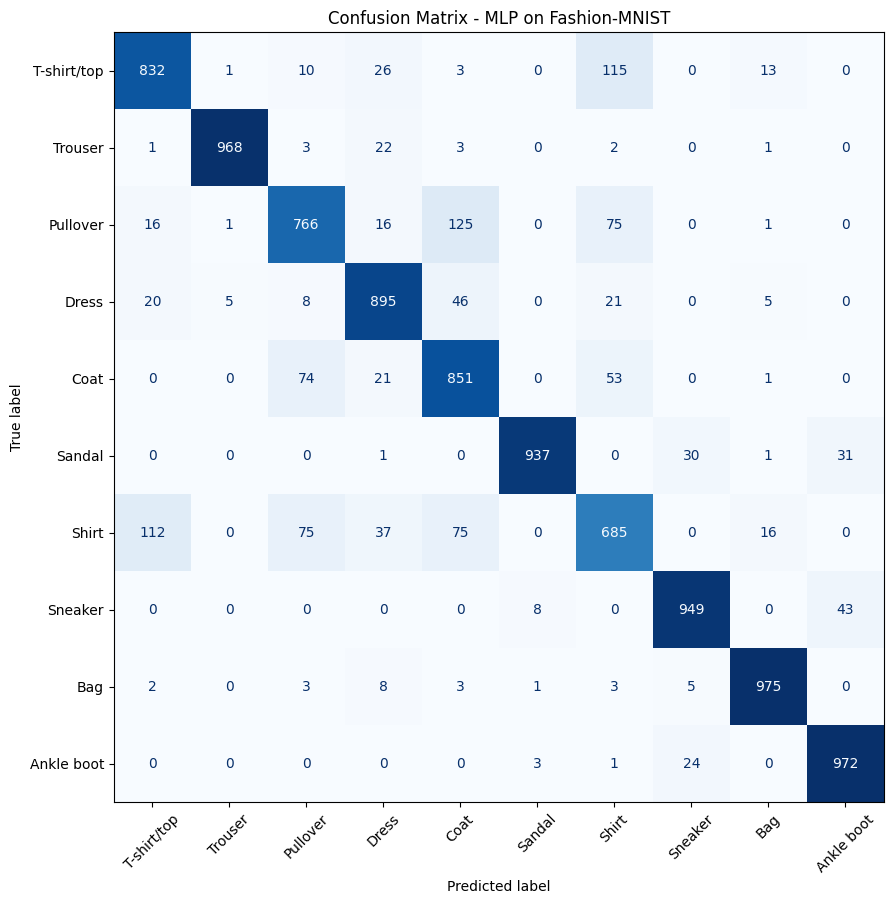

In [259]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - MLP on Fashion-MNIST")
plt.show()

###  đọc kết quả

- Giá trị trên đường chéo: số mẫu dự đoán đúng.
- Giá trị ngoài đường chéo: các trường hợp bị nhầm lớp.

### Phân tích thực tế

Với Fashion-MNIST, mô hình thường dễ nhầm các nhóm có hình dạng tương tự nhau như:
- Shirt và T-shirt/top;
- Shirt và Pullover;
- Coat và Pullover.

Confusion matrix cho phép nhìn rõ loại lỗi này hơn accuracy.

## 16. Classification Report

Ta xem thêm:
- precision;
- recall;
- F1-score;
- support.

Mục tiêu ở đây không phải học lại toàn bộ metric của bài 3, mà là biết cách kiểm tra hiệu năng theo từng lớp.

In [260]:
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

 T-shirt/top     0.8464    0.8320    0.8391      1000
     Trouser     0.9928    0.9680    0.9803      1000
    Pullover     0.8158    0.7660    0.7901      1000
       Dress     0.8723    0.8950    0.8835      1000
        Coat     0.7694    0.8510    0.8082      1000
      Sandal     0.9874    0.9370    0.9615      1000
       Shirt     0.7173    0.6850    0.7008      1000
     Sneaker     0.9415    0.9490    0.9452      1000
         Bag     0.9625    0.9750    0.9687      1000
  Ankle boot     0.9293    0.9720    0.9501      1000

    accuracy                         0.8830     10000
   macro avg     0.8835    0.8830    0.8828     10000
weighted avg     0.8835    0.8830    0.8828     10000



###  đọc kết quả

- `precision`: trong các mẫu mô hình dự đoán là một lớp, bao nhiêu mẫu đúng.
- `recall`: trong các mẫu thực sự thuộc lớp đó, mô hình tìm đúng bao nhiêu.
- `f1-score`: cân bằng precision và recall.

### Phân tích thực tế

Dù dữ liệu cân bằng, một số lớp vẫn có F1 thấp hơn vì bản thân hình ảnh giữa các lớp đó khó phân biệt.

## 17. Trực quan hóa các dự đoán

Ta hiển thị một số ảnh cùng:
- nhãn thật;
- nhãn dự đoán;
- xác suất cao nhất.

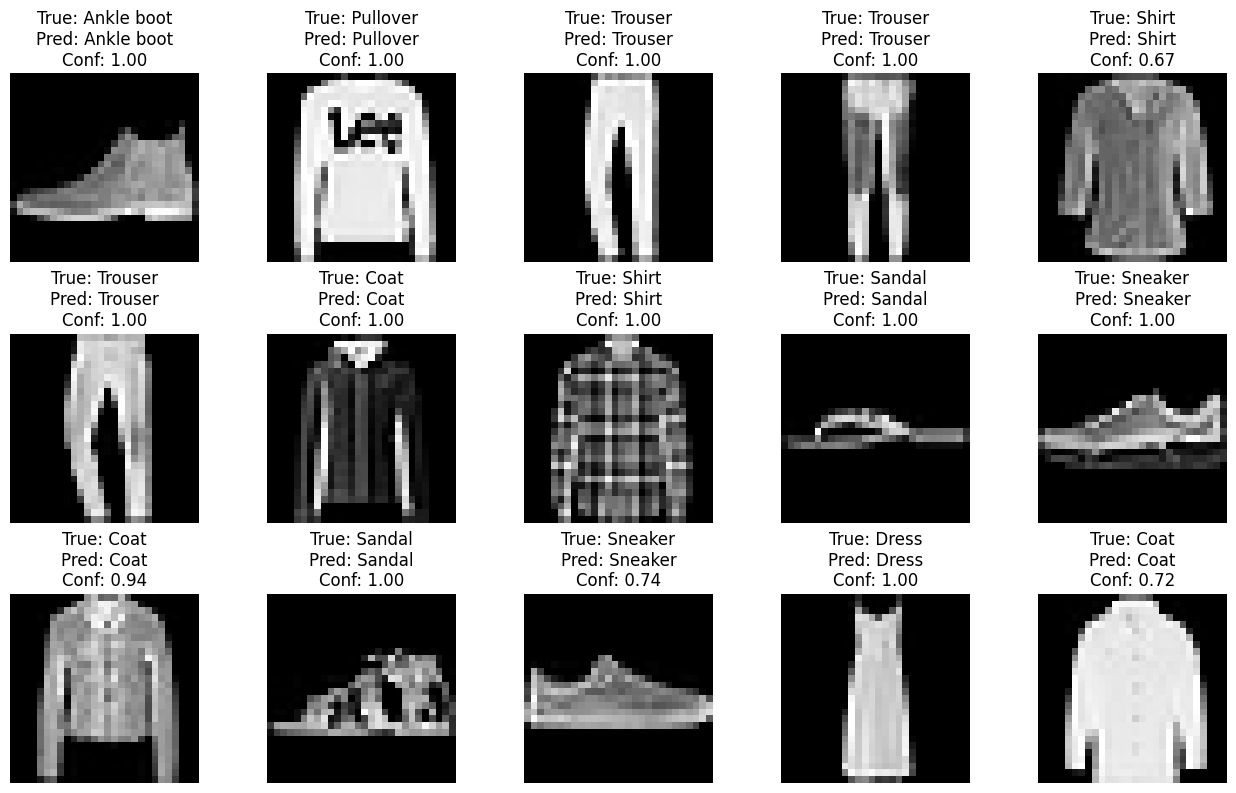

In [261]:
indices = np.arange(15)

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(indices, axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

###  đọc kết quả

Mỗi ảnh cho biết:
- lớp thật;
- lớp mô hình chọn;
- confidence của lớp được chọn.

### Phân tích thực tế

Các mẫu dự đoán sai nhưng confidence cao là những ví dụ rất quan trọng để phân tích lỗi mô hình. Trong các bài toán thực tế, đây thường là nhóm cần được điều tra sâu hơn.

## 18. Phân tích các mẫu dự đoán sai

Thay vì chỉ xem accuracy, ta chủ động tìm các ảnh mà mô hình dự đoán sai.

Số mẫu dự đoán sai: 1170


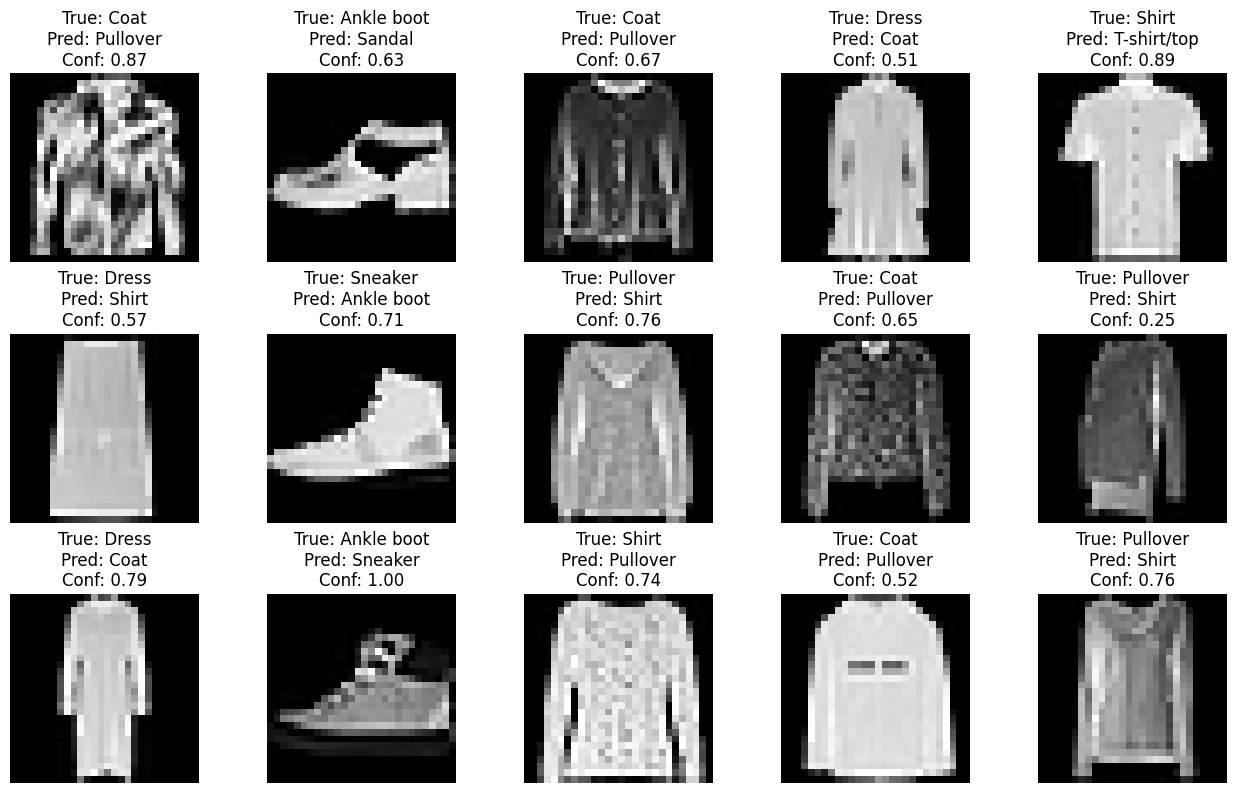

In [262]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Số mẫu dự đoán sai:", len(wrong_indices))

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(wrong_indices[:15], axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### đọc kết quả

Chỉ các mẫu mô hình dự đoán sai được hiển thị.

### Phân tích thực tế

Error analysis là bước quan trọng của workflow Deep Learning. Từ lỗi thực tế, ta mới quyết định có cần:
- mô hình sâu hơn;
- regularization;
- thêm dữ liệu;
- data augmentation;
- đổi kiến trúc sang CNN.

## 19. Inference trên một ảnh riêng lẻ

Trong thực tế, mô hình thường nhận một hoặc một vài mẫu mới chứ không phải cả test set.

Ta chọn một ảnh và mô phỏng quy trình inference.

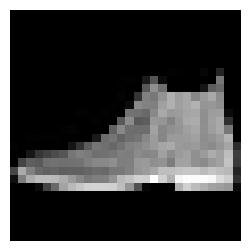

True label : Ankle boot
Prediction : Ankle boot
Confidence : 0.9959707856178284


In [263]:
sample_image = X_test[0]
sample_true_label = y_test[0]

sample_prob = model.predict(sample_image[None, ...], verbose=0)[0]
sample_pred = np.argmax(sample_prob)

plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap="gray")
plt.axis("off")
plt.show()

print("True label :", class_names[sample_true_label])
print("Prediction :", class_names[sample_pred])
print("Confidence :", float(sample_prob[sample_pred]))

### đọc kết quả

`sample_image[None, ...]` thêm chiều batch:

- trước: `(28, 28)`
- sau: `(1, 28, 28)`

### Phân tích thực tế

Framework Deep Learning thường yêu cầu input có batch dimension ngay cả khi chỉ dự đoán một ảnh.

## 20. Lưu và khôi phục mô hình

Sau khi huấn luyện xong, mô hình cần được lưu để:
- triển khai;
- tiếp tục huấn luyện;
- tái sử dụng sau này.

Keras cho phép lưu toàn bộ kiến trúc và trọng số vào file `.keras`.

In [264]:
final_model_path = "fashion_mnist_mlp_final.keras"

model.save(final_model_path)

loaded_model = tf.keras.models.load_model(final_model_path)

loaded_loss, loaded_acc = loaded_model.evaluate(test_ds, verbose=0)

print("Loaded model test accuracy:", round(float(loaded_acc), 4))

Loaded model test accuracy: 0.883


###  đọc kết quả

Nếu accuracy sau khi load gần như giống mô hình trước khi lưu, quá trình lưu/khôi phục đã thành công.

### Phân tích thực tế

Đây là bước nối từ training sang deployment. Trong dự án thật, model artifact cần được quản lý cùng:
- phiên bản dữ liệu;
- hyperparameter;
- code;
- metric.

# 21. Tổng kết workflow Deep Learning

Một workflow Deep Learning điển hình:

**Bước 1. Chuẩn bị dữ liệu**  
↓  
**Bước 2. Train / Validation / Test split**  
↓  
**Bước 3. Tiền xử lý và tạo batch**  
↓  
**Bước 4. Xây dựng kiến trúc mạng**  
↓  
**Bước 5. Compile: optimizer + loss + metric**  
↓  
**Bước 6. Train bằng mini-batch**  
↓  
**Bước 7. Theo dõi validation và callback**  
↓  
**Bước 8. Phân tích learning curves**  
↓  
**Bước 9. Đánh giá trên test set**  
↓  
**Bước 10. Error analysis**  
↓  
**Bước 11. Inference và lưu mô hình**

---

## So sánh nhanh với workflow Machine Learning cổ điển

| Machine Learning cổ điển | Deep Learning |
|---|---|
| Feature engineering thường rất quan trọng | Mô hình học representation từ dữ liệu |
| `fit(X_train, y_train)` thường là một bước tương đối gọn | Training gồm nhiều epoch và mini-batch |
| Ít cần quan sát quá trình tối ưu | Cần theo dõi loss/metric theo epoch |
| Model selection dựa nhiều vào CV | Validation set và learning curve rất quan trọng |
| Model thường nhỏ | Số parameter có thể rất lớn |
| Training nhanh | Training có thể tốn GPU và thời gian |


# 22. Bài tập mở rộng cho sinh viên

### Bài 1. Thay đổi kiến trúc
Thử các mô hình:
- 1 hidden layer;
- 2 hidden layers;
- 3 hidden layers.

So sánh:
- số parameter;
- thời gian train;
- validation accuracy;
- test accuracy.

### Bài 2. Thử learning rate
Huấn luyện với:
- `1e-2`
- `1e-3`
- `1e-4`

Nhận xét learning curve.

### Bài 3. Thử batch size
So sánh:
- 32
- 128
- 512

Nhận xét tốc độ và kết quả.

### Bài 4. Thêm Dropout
Thêm `Dropout(0.3)` giữa các Dense layer.  
Quan sát khoảng cách train/validation accuracy.

### Bài 5. Thêm L2 regularization
Dùng `kernel_regularizer=tf.keras.regularizers.l2(...)`.

### Bài 6. Phân tích lỗi
Tìm 20 mẫu mô hình dự đoán sai với confidence cao nhất.  
Phân tích vì sao chúng khó.
---

## Yêu cầu báo cáo ngắn

Sinh viên cần trả lời:

1. Kiến trúc mô hình đã sử dụng.
2. Optimizer, loss, learning rate, batch size.
3. Epoch tốt nhất.
4. Training/validation learning curves.
5. Test accuracy.
6. Hai cặp lớp bị nhầm nhiều nhất.
7. Nhận xét underfitting/overfitting.
8. Một thay đổi đã thử để cải thiện mô hình và kết quả.

# BÀI TẬP MỞ RỘNG

## Bài 1. Thay đổi kiến trúc mạng MLP

Tiến hành thực nghiệm với ba kiến trúc mạng MLP gồm:
- Mô hình 1 tầng ẩn: 256 neuron.
- Mô hình 2 tầng ẩn: 256 và 128 neuron.
- Mô hình 3 tầng ẩn: 256, 128 và 64 neuron.

Giữ nguyên learning rate = 0.001, batch size = 64 và sử dụng EarlyStopping.

So sánh số lượng tham số, thời gian huấn luyện, Validation Accuracy và Test Accuracy.

In [265]:

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

architectures = {
    "1 tầng ẩn (256)": [256],
    "2 tầng ẩn (256-128)": [256, 128],
    "3 tầng ẩn (256-128-64)": [256, 128, 64]
}

bai1_results = []
bai1_histories = {}
bai1_models = {}

for name, hidden_layers in architectures.items():

    print("\n" + "=" * 60)
    print("ĐANG HUẤN LUYỆN:", name)
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    layers = [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten()
    ]

    for units in hidden_layers:
        layers.append(
            tf.keras.layers.Dense(units, activation="relu")
        )

    layers.append(
        tf.keras.layers.Dense(10, activation="softmax")
    )

    experiment_model = tf.keras.Sequential(layers)

    experiment_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    parameter_count = experiment_model.count_params()

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    experiment_history = experiment_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.time() - start_time

    best_epoch = (
        np.argmin(experiment_history.history["val_loss"]) + 1
    )

    val_loss, val_accuracy = experiment_model.evaluate(
        X_val, y_val, verbose=0
    )

    test_loss, test_accuracy = experiment_model.evaluate(
        X_test, y_test, verbose=0
    )

    bai1_results.append({
        "Kiến trúc": name,
        "Số tầng ẩn": len(hidden_layers),
        "Số tham số": parameter_count,
        "Epoch tốt nhất": best_epoch,
        "Epoch đã chạy": len(experiment_history.history["loss"]),
        "Thời gian (giây)": round(training_time, 2),
        "Validation Accuracy (%)": round(val_accuracy * 100, 2),
        "Test Accuracy (%)": round(test_accuracy * 100, 2)
    })

    bai1_histories[name] = experiment_history.history
    bai1_models[name] = experiment_model

    print("\nKẾT QUẢ:", name)
    print("Số tham số:", parameter_count)
    print("Epoch tốt nhất:", best_epoch)
    print("Thời gian:", round(training_time, 2), "giây")
    print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

bai1_df = pd.DataFrame(bai1_results)

print("\n" + "=" * 70)
print("BẢNG SO SÁNH KẾT QUẢ BÀI 1")
print("=" * 70)

display(bai1_df)



ĐANG HUẤN LUYỆN: 1 tầng ẩn (256)
Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8196 - loss: 0.5119 - val_accuracy: 0.8487 - val_loss: 0.4209
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8631 - loss: 0.3766 - val_accuracy: 0.8653 - val_loss: 0.3780
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8777 - loss: 0.3352 - val_accuracy: 0.8701 - val_loss: 0.3644
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8875 - loss: 0.3082 - val_accuracy: 0.8736 - val_loss: 0.3575
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8943 - loss: 0.2880 - val_accuracy: 0.8740 - val_loss: 0.3547
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9015 - loss: 0.2722 - val_accuracy: 0.8762 - val_loss: 0.3490
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9066 - loss: 0.2567 - val_accuracy: 0.8786 - val_loss: 0.3444
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9110

,Kiến trúc,Số tầng ẩn,Số tham số,Epoch tốt nhất,Epoch đã chạy,Thời gian (giây),Validation Accuracy (%),Test Accuracy (%)
0,1 tầng ẩn (256),1,203530,10,13,34.84,88.42,87.59
1,2 tầng ẩn (256-128),2,235146,6,9,25.27,88.34,87.43
2,3 tầng ẩn (256-128-64),3,242762,3,6,19.01,87.31,86.67


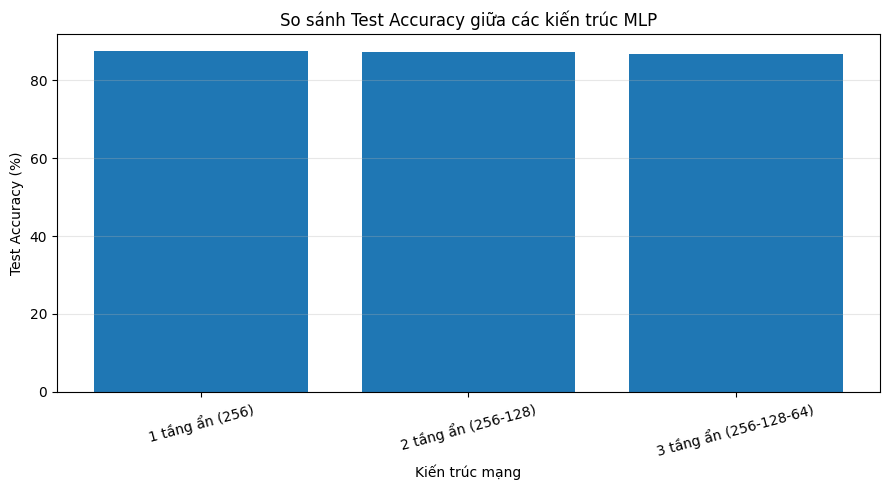

In [266]:

plt.figure(figsize=(9, 5))

plt.bar(
    bai1_df["Kiến trúc"],
    bai1_df["Test Accuracy (%)"]
)

plt.title("So sánh Test Accuracy giữa các kiến trúc MLP")
plt.xlabel("Kiến trúc mạng")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Bài 2. Thử nghiệm các mức Learning Rate

Tiến hành huấn luyện mô hình MLP với ba mức Learning Rate:
- 0.01
- 0.001
- 0.0001

Giữ nguyên kiến trúc hai tầng ẩn (256, 128), batch size = 64 và sử dụng EarlyStopping.

So sánh kết quả thông qua validation loss, validation accuracy, test accuracy và learning curves.

In [267]:

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

learning_rates = [1e-2, 1e-3, 1e-4]

bai2_results = []
bai2_histories = {}
bai2_models = {}

for lr in learning_rates:

    print("\n" + "=" * 60)
    print("ĐANG THỬ LEARNING RATE:", lr)
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    lr_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    lr_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    lr_history = lr_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.time() - start_time

    best_epoch = np.argmin(
        lr_history.history["val_loss"]
    ) + 1

    best_val_loss = min(
        lr_history.history["val_loss"]
    )

    val_loss, val_accuracy = lr_model.evaluate(
        X_val, y_val, verbose=0
    )

    test_loss, test_accuracy = lr_model.evaluate(
        X_test, y_test, verbose=0
    )

    bai2_results.append({
        "Learning Rate": lr,
        "Epoch tốt nhất": best_epoch,
        "Epoch đã chạy": len(lr_history.history["loss"]),
        "Validation Loss": round(best_val_loss, 4),
        "Validation Accuracy (%)": round(val_accuracy * 100, 2),
        "Test Accuracy (%)": round(test_accuracy * 100, 2),
        "Thời gian (giây)": round(training_time, 2)
    })

    bai2_histories[lr] = lr_history.history
    bai2_models[lr] = lr_model

    print("\nKẾT QUẢ LEARNING RATE:", lr)
    print("Epoch tốt nhất:", best_epoch)
    print("Validation Loss:", round(best_val_loss, 4))
    print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Thời gian:", round(training_time, 2), "giây")

bai2_df = pd.DataFrame(bai2_results)

print("\nBẢNG SO SÁNH LEARNING RATE")
display(bai2_df)



ĐANG THỬ LEARNING RATE: 0.01
Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8053 - loss: 0.5422 - val_accuracy: 0.8460 - val_loss: 0.4228
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8473 - loss: 0.4184 - val_accuracy: 0.8457 - val_loss: 0.4286
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8602 - loss: 0.3863 - val_accuracy: 0.8449 - val_loss: 0.4488
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8647 - loss: 0.3710 - val_accuracy: 0.8614 - val_loss: 0.3950
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8675 - loss: 0.3649 - val_accuracy: 0.8614 - val_loss: 0.3988
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8710 - loss: 0.3563 - val_accuracy: 0.8543 - val_loss: 0.3976
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8738 - loss: 0.3508 - val_accuracy: 0.8579 - val_loss: 0.4221

KẾT QUẢ LEARNING RATE: 0.01
Epoch tốt nhất: 4
Validation Loss: 0.395
Vali

,Learning Rate,Epoch tốt nhất,Epoch đã chạy,Validation Loss,Validation Accuracy (%),Test Accuracy (%),Thời gian (giây)
0,0.0100,4,7,0.3950,86.14,85.18,20.81
1,0.0010,6,9,0.3316,88.34,87.43,27.55
2,0.0001,28,31,0.3203,88.53,87.98,82.92


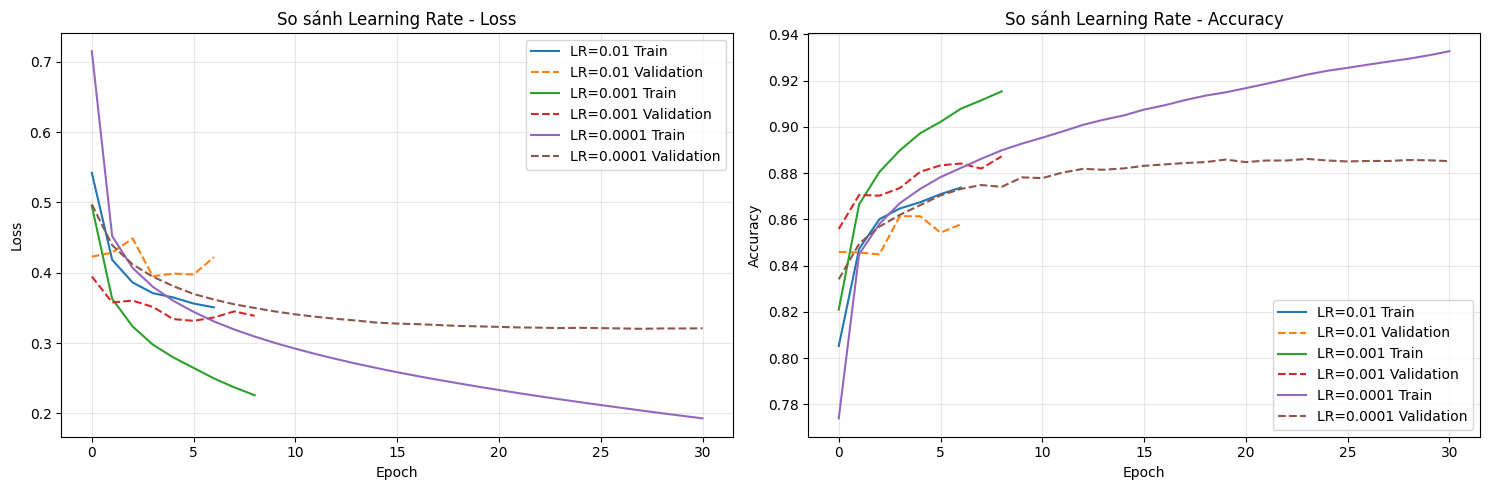

In [268]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for lr, hist in bai2_histories.items():

    axes[0].plot(
        hist["loss"],
        label=f"LR={lr} Train"
    )

    axes[0].plot(
        hist["val_loss"],
        linestyle="--",
        label=f"LR={lr} Validation"
    )

    axes[1].plot(
        hist["accuracy"],
        label=f"LR={lr} Train"
    )

    axes[1].plot(
        hist["val_accuracy"],
        linestyle="--",
        label=f"LR={lr} Validation"
    )

axes[0].set_title("So sánh Learning Rate - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("So sánh Learning Rate - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Bài 3. Thử nghiệm thay đổi Batch Size

Tiến hành thực nghiệm với ba giá trị Batch Size:
- Batch Size = 32
- Batch Size = 128
- Batch Size = 512

Giữ nguyên kiến trúc MLP hai tầng ẩn (256, 128), Learning Rate = 0.001 và Optimizer Adam.

So sánh thời gian huấn luyện, thời gian trung bình mỗi epoch, Validation Accuracy và Test Accuracy.

In [269]:

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

batch_sizes = [32, 128, 512]

bai3_results = []
bai3_histories = {}
bai3_models = {}

for batch_size in batch_sizes:

    print("\n" + "=" * 60)
    print("ĐANG THỬ BATCH SIZE:", batch_size)
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    batch_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    batch_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    batch_history = batch_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.time() - start_time

    epochs_run = len(batch_history.history["loss"])
    seconds_per_epoch = training_time / epochs_run

    best_epoch = np.argmin(
        batch_history.history["val_loss"]
    ) + 1

    best_val_loss = min(
        batch_history.history["val_loss"]
    )

    val_loss, val_accuracy = batch_model.evaluate(
        X_val, y_val, verbose=0
    )

    test_loss, test_accuracy = batch_model.evaluate(
        X_test, y_test, verbose=0
    )

    bai3_results.append({
        "Batch Size": batch_size,
        "Epoch tốt nhất": best_epoch,
        "Epoch đã chạy": epochs_run,
        "Thời gian train (giây)": round(training_time, 2),
        "Thời gian/epoch (giây)": round(seconds_per_epoch, 2),
        "Validation Loss": round(best_val_loss, 4),
        "Validation Accuracy (%)": round(val_accuracy * 100, 2),
        "Test Accuracy (%)": round(test_accuracy * 100, 2)
    })

    bai3_histories[batch_size] = batch_history.history
    bai3_models[batch_size] = batch_model

    print("\nKẾT QUẢ BATCH SIZE:", batch_size)
    print("Epoch tốt nhất:", best_epoch)
    print("Epoch đã chạy:", epochs_run)
    print("Thời gian train:", round(training_time, 2), "giây")
    print("Thời gian trung bình mỗi epoch:", round(seconds_per_epoch, 2), "giây")
    print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

bai3_df = pd.DataFrame(bai3_results)

print("\n" + "=" * 70)
print("BẢNG SO SÁNH KẾT QUẢ BÀI 3")
print("=" * 70)

display(bai3_df)



ĐANG THỬ BATCH SIZE: 32
Epoch 1/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8235 - loss: 0.4874 - val_accuracy: 0.8568 - val_loss: 0.3947
Epoch 2/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8651 - loss: 0.3638 - val_accuracy: 0.8738 - val_loss: 0.3591
Epoch 3/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8795 - loss: 0.3243 - val_accuracy: 0.8761 - val_loss: 0.3406
Epoch 4/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8879 - loss: 0.2998 - val_accuracy: 0.8761 - val_loss: 0.3395
Epoch 5/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8950 - loss: 0.2786 - val_accuracy: 0.8748 - val_loss: 0.3547
Epoch 6/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9020 - loss: 0.2620 - val_accuracy: 0.8758 - val_loss: 0.3576
Epoch 7/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9063 - loss: 0.2486 - val_accuracy: 0.8751 - val_loss: 0.3738

KẾT QUẢ BATCH SIZE: 32
Epoch tốt nhất: 4
Epoch đã chạy: 7
Thời g

,Batch Size,Epoch tốt nhất,Epoch đã chạy,Thời gian train (giây),Thời gian/epoch (giây),Validation Loss,Validation Accuracy (%),Test Accuracy (%)
0,32,4,7,36.94,5.28,0.3395,87.61,86.74
1,128,7,10,16.03,1.60,0.3351,88.21,87.70
2,512,8,11,7.95,0.72,0.3343,88.01,87.59


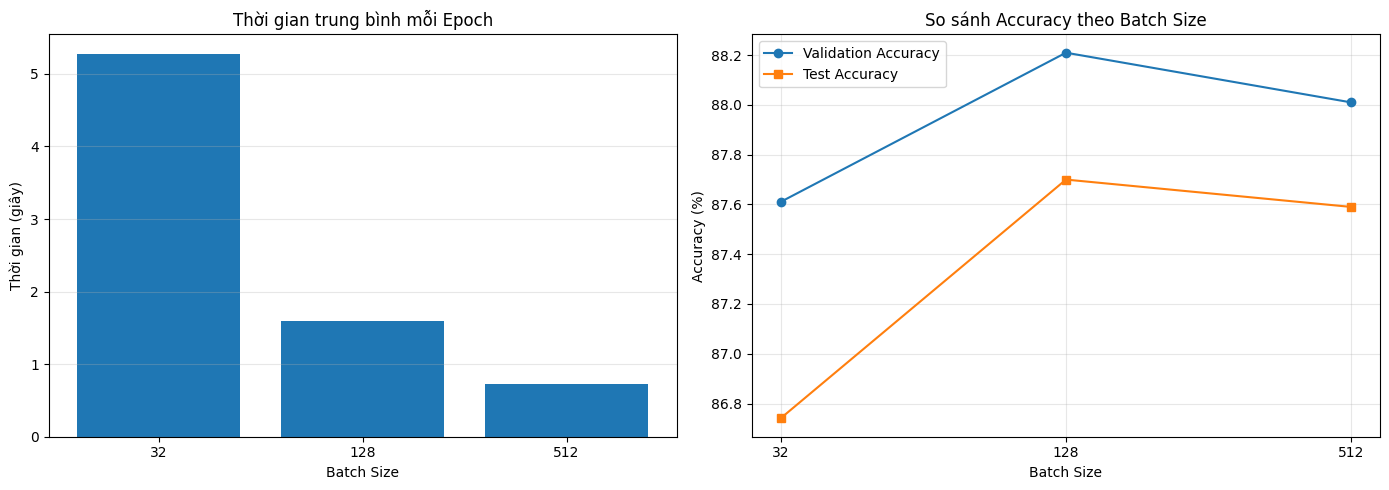

In [270]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    bai3_df["Batch Size"].astype(str),
    bai3_df["Thời gian/epoch (giây)"]
)

axes[0].set_title("Thời gian trung bình mỗi Epoch")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Thời gian (giây)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].plot(
    bai3_df["Batch Size"].astype(str),
    bai3_df["Validation Accuracy (%)"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].plot(
    bai3_df["Batch Size"].astype(str),
    bai3_df["Test Accuracy (%)"],
    marker="s",
    label="Test Accuracy"
)

axes[1].set_title("So sánh Accuracy theo Batch Size")
axes[1].set_xlabel("Batch Size")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Bài 4. Thêm Dropout để hạn chế Overfitting

Bổ sung lớp Dropout với tỷ lệ 0.3 vào giữa hai tầng ẩn của mạng MLP.

So sánh mô hình đối chứng và mô hình có Dropout về Train Accuracy, Validation Accuracy, Test Accuracy và chênh lệch Train/Validation.

Giữ nguyên kiến trúc, Learning Rate, Batch Size và các tham số huấn luyện khác.

In [271]:

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

bai4_results = []
bai4_histories = {}
bai4_models = {}

configs = {
    "Đối chứng": False,
    "Dropout 0.3": True
}

for name, use_dropout in configs.items():

    print("\n" + "=" * 60)
    print("ĐANG HUẤN LUYỆN:", name)
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    layers = [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu")
    ]

    if use_dropout:
        layers.append(tf.keras.layers.Dropout(0.3))

    layers.extend([
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model = tf.keras.Sequential(layers)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.time() - start_time

    train_loss, train_accuracy = model.evaluate(
        X_train, y_train, verbose=0
    )

    val_loss, val_accuracy = model.evaluate(
        X_val, y_val, verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    best_epoch = np.argmin(
        history.history["val_loss"]
    ) + 1

    gap = (train_accuracy - val_accuracy) * 100

    bai4_results.append({
        "Mô hình": name,
        "Epoch tốt nhất": best_epoch,
        "Train Accuracy (%)": round(train_accuracy * 100, 2),
        "Validation Accuracy (%)": round(val_accuracy * 100, 2),
        "Test Accuracy (%)": round(test_accuracy * 100, 2),
        "Chênh lệch Train-Val (%)": round(gap, 2),
        "Thời gian (giây)": round(training_time, 2)
    })

    bai4_histories[name] = history.history
    bai4_models[name] = model

    print("\nKẾT QUẢ:", name)
    print("Train Accuracy:", round(train_accuracy * 100, 2), "%")
    print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Chênh lệch Train-Val:", round(gap, 2), "%")
    print("Thời gian:", round(training_time, 2), "giây")

bai4_df = pd.DataFrame(bai4_results)

print("\nBẢNG SO SÁNH BÀI 4")
display(bai4_df)



ĐANG HUẤN LUYỆN: Đối chứng
Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8210 - loss: 0.4950 - val_accuracy: 0.8559 - val_loss: 0.3948
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8665 - loss: 0.3630 - val_accuracy: 0.8706 - val_loss: 0.3578
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8806 - loss: 0.3238 - val_accuracy: 0.8703 - val_loss: 0.3605
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8899 - loss: 0.2978 - val_accuracy: 0.8736 - val_loss: 0.3514
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8973 - loss: 0.2797 - val_accuracy: 0.8806 - val_loss: 0.3342
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9022 - loss: 0.2647 - val_accuracy: 0.8834 - val_loss: 0.3316
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9079 - loss: 0.2497 - val_accuracy: 0.8842 - val_loss: 0.3364
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9115 - los

,Mô hình,Epoch tốt nhất,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Chênh lệch Train-Val (%),Thời gian (giây)
0,Đối chứng,6,90.47,88.34,87.43,2.13,25.15
1,Dropout 0.3,10,90.59,88.44,87.62,2.15,36.71


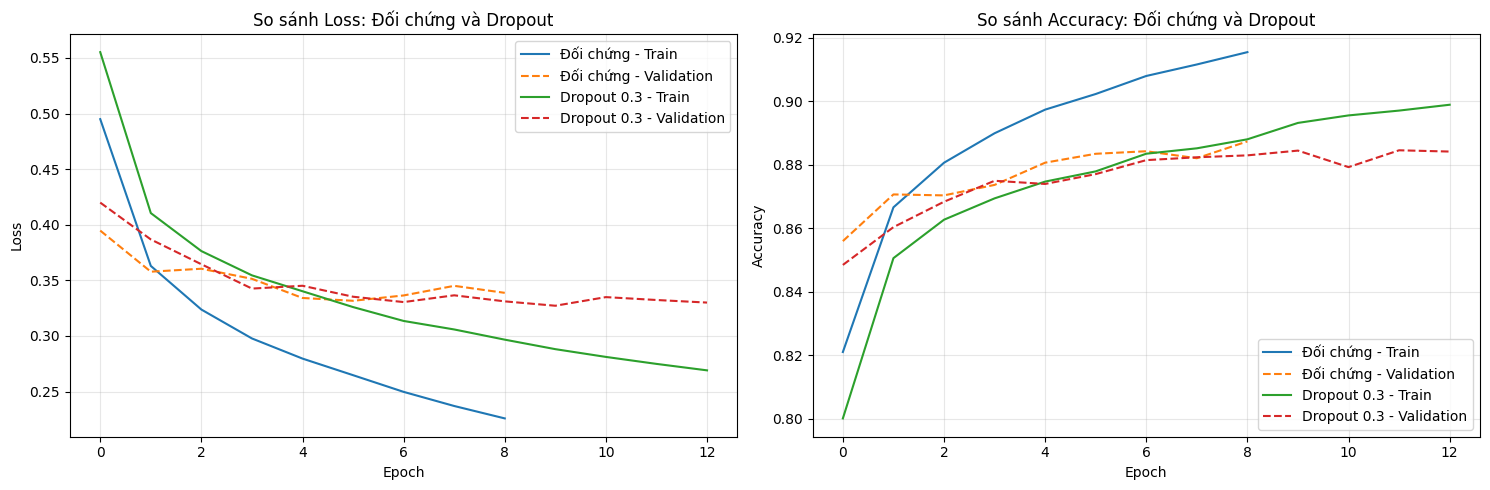

In [272]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, hist in bai4_histories.items():

    axes[0].plot(
        hist["loss"],
        label=f"{name} - Train"
    )

    axes[0].plot(
        hist["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

    axes[1].plot(
        hist["accuracy"],
        label=f"{name} - Train"
    )

    axes[1].plot(
        hist["val_accuracy"],
        linestyle="--",
        label=f"{name} - Validation"
    )

axes[0].set_title("So sánh Loss: Đối chứng và Dropout")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("So sánh Accuracy: Đối chứng và Dropout")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Bài 5. Thêm điều chuẩn L2 (L2 Regularization)

Bổ sung điều chuẩn L2 với hệ số 0.0001 vào trọng số của hai tầng Dense ẩn trong mô hình MLP.

So sánh mô hình đối chứng và mô hình có L2 về Train Accuracy, Validation Accuracy, Test Accuracy và chênh lệch Train/Validation.

Giữ nguyên kiến trúc MLP, Learning Rate, Batch Size và các tham số huấn luyện khác.

In [273]:

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

l2_value = 0.0001

bai5_results = []
bai5_histories = {}
bai5_models = {}

configs = {
    "Đối chứng": False,
    "L2 = 0.0001": True
}

for name, use_l2 in configs.items():

    print("\n" + "=" * 60)
    print("ĐANG HUẤN LUYỆN:", name)
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    regularizer = (
        tf.keras.regularizers.l2(l2_value)
        if use_l2 else None
    )

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=regularizer
        ),

        tf.keras.layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizer
        ),

        tf.keras.layers.Dense(
            10,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.time() - start_time

    train_loss, train_accuracy = model.evaluate(
        X_train, y_train, verbose=0
    )

    val_loss, val_accuracy = model.evaluate(
        X_val, y_val, verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    best_epoch = np.argmin(
        history.history["val_loss"]
    ) + 1

    gap = (train_accuracy - val_accuracy) * 100

    bai5_results.append({
        "Mô hình": name,
        "Epoch tốt nhất": best_epoch,
        "Epoch đã chạy": len(history.history["loss"]),
        "Train Accuracy (%)": round(train_accuracy * 100, 2),
        "Validation Accuracy (%)": round(val_accuracy * 100, 2),
        "Test Accuracy (%)": round(test_accuracy * 100, 2),
        "Chênh lệch Train-Val (%)": round(gap, 2),
        "Thời gian (giây)": round(training_time, 2)
    })

    bai5_histories[name] = history.history
    bai5_models[name] = model

    print("\nKẾT QUẢ:", name)
    print("Epoch tốt nhất:", best_epoch)
    print("Train Accuracy:", round(train_accuracy * 100, 2), "%")
    print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Chênh lệch Train-Val:", round(gap, 2), "%")
    print("Thời gian:", round(training_time, 2), "giây")

bai5_df = pd.DataFrame(bai5_results)

print("\n" + "=" * 70)
print("BẢNG SO SÁNH KẾT QUẢ BÀI 5")
print("=" * 70)

display(bai5_df)



ĐANG HUẤN LUYỆN: Đối chứng
Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8210 - loss: 0.4950 - val_accuracy: 0.8559 - val_loss: 0.3948
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8665 - loss: 0.3630 - val_accuracy: 0.8706 - val_loss: 0.3578
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8806 - loss: 0.3238 - val_accuracy: 0.8703 - val_loss: 0.3605
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8899 - loss: 0.2978 - val_accuracy: 0.8736 - val_loss: 0.3514
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8973 - loss: 0.2797 - val_accuracy: 0.8806 - val_loss: 0.3342
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9022 - loss: 0.2647 - val_accuracy: 0.8834 - val_loss: 0.3316
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9079 - loss: 0.2497 - val_accuracy: 0.8842 - val_loss: 0.3364
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9115 - los

,Mô hình,Epoch tốt nhất,Epoch đã chạy,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Chênh lệch Train-Val (%),Thời gian (giây)
0,Đối chứng,6,9,90.47,88.34,87.43,2.13,28.74
1,L2 = 0.0001,10,13,91.18,88.56,87.69,2.62,35.78


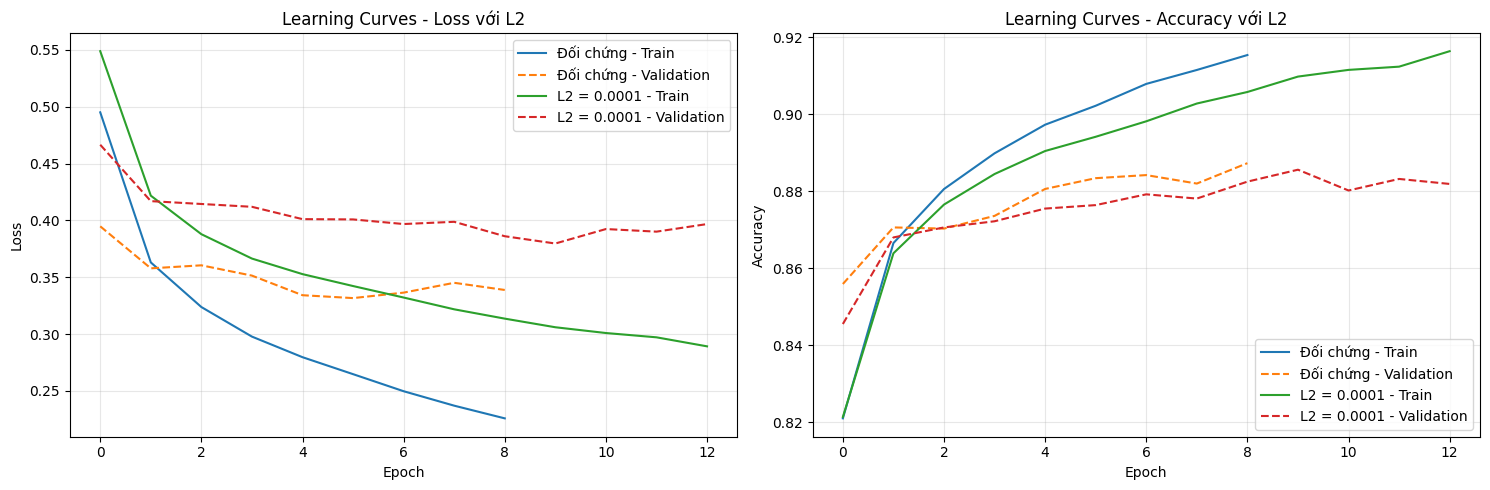

In [274]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, hist in bai5_histories.items():

    axes[0].plot(
        hist["loss"],
        label=f"{name} - Train"
    )

    axes[0].plot(
        hist["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

    axes[1].plot(
        hist["accuracy"],
        label=f"{name} - Train"
    )

    axes[1].plot(
        hist["val_accuracy"],
        linestyle="--",
        label=f"{name} - Validation"
    )

axes[0].set_title("Learning Curves - Loss với L2")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Learning Curves - Accuracy với L2")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Bài 6. Phân tích 20 ảnh dự đoán sai có Confidence cao nhất

Sử dụng mô hình MLP đối chứng để dự đoán trên toàn bộ tập dữ liệu test gồm 10.000 ảnh.

Xác định các ảnh có nhãn dự đoán khác nhãn thực tế, sắp xếp theo Confidence giảm dần và hiển thị 20 ảnh dự đoán sai có Confidence cao nhất.

Đồng thời thống kê hai cặp lớp bị nhầm lẫn nhiều nhất trên toàn bộ tập test.

In [275]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# Ten cac lop trong Fashion-MNIST
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

# Su dung mo hinh doi chung 2 tang an tu Bai 1
baseline_model = bai1_models["2 tầng ẩn (256-128)"]

# Chuan bi nhan that
y_true = np.asarray(y_test).reshape(-1).astype(int)

# Du doan tren toan bo tap test
y_prob = baseline_model.predict(
    X_test,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

# Confidence cua lop duoc du doan
confidence = np.max(y_prob, axis=1)

# Tim cac anh du doan sai
wrong_indices = np.where(y_pred != y_true)[0]

# Sap xep theo confidence giam dan
sorted_wrong = wrong_indices[
    np.argsort(confidence[wrong_indices])[::-1]
]

# Lay 20 anh sai co confidence cao nhat
top20_indices = sorted_wrong[:20]

# Tao bang ket qua
bai6_df = pd.DataFrame({
    "STT": np.arange(1, len(top20_indices) + 1),
    "Vi tri anh test": top20_indices,
    "Nhan thuc te": [
        class_names[y_true[i]] for i in top20_indices
    ],
    "Nhan du doan": [
        class_names[y_pred[i]] for i in top20_indices
    ],
    "Confidence (%)": [
        round(confidence[i] * 100, 2)
        for i in top20_indices
    ]
})

print("TONG SO ANH DU DOAN SAI:", len(wrong_indices))
print("\n20 ANH DU DOAN SAI CO CONFIDENCE CAO NHAT")

display(bai6_df)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
TONG SO ANH DU DOAN SAI: 1257

20 ANH DU DOAN SAI CO CONFIDENCE CAO NHAT


,STT,Vi tri anh test,Nhan thuc te,Nhan du doan,Confidence (%)
0,1,4394,Dress,Bag,100.000000
1,2,3487,Sandal,Ankle boot,99.989998
2,3,5946,Ankle boot,Sandal,99.989998
3,4,9059,Dress,Trouser,99.959999
4,5,3866,Sandal,Ankle boot,99.959999
5,6,324,Coat,Shirt,99.959999
6,7,7734,Sandal,Ankle boot,99.919998
7,8,7936,Ankle boot,Sneaker,99.889999
8,9,1300,Bag,Sandal,99.849998
9,10,9574,Pullover,Shirt,99.839996


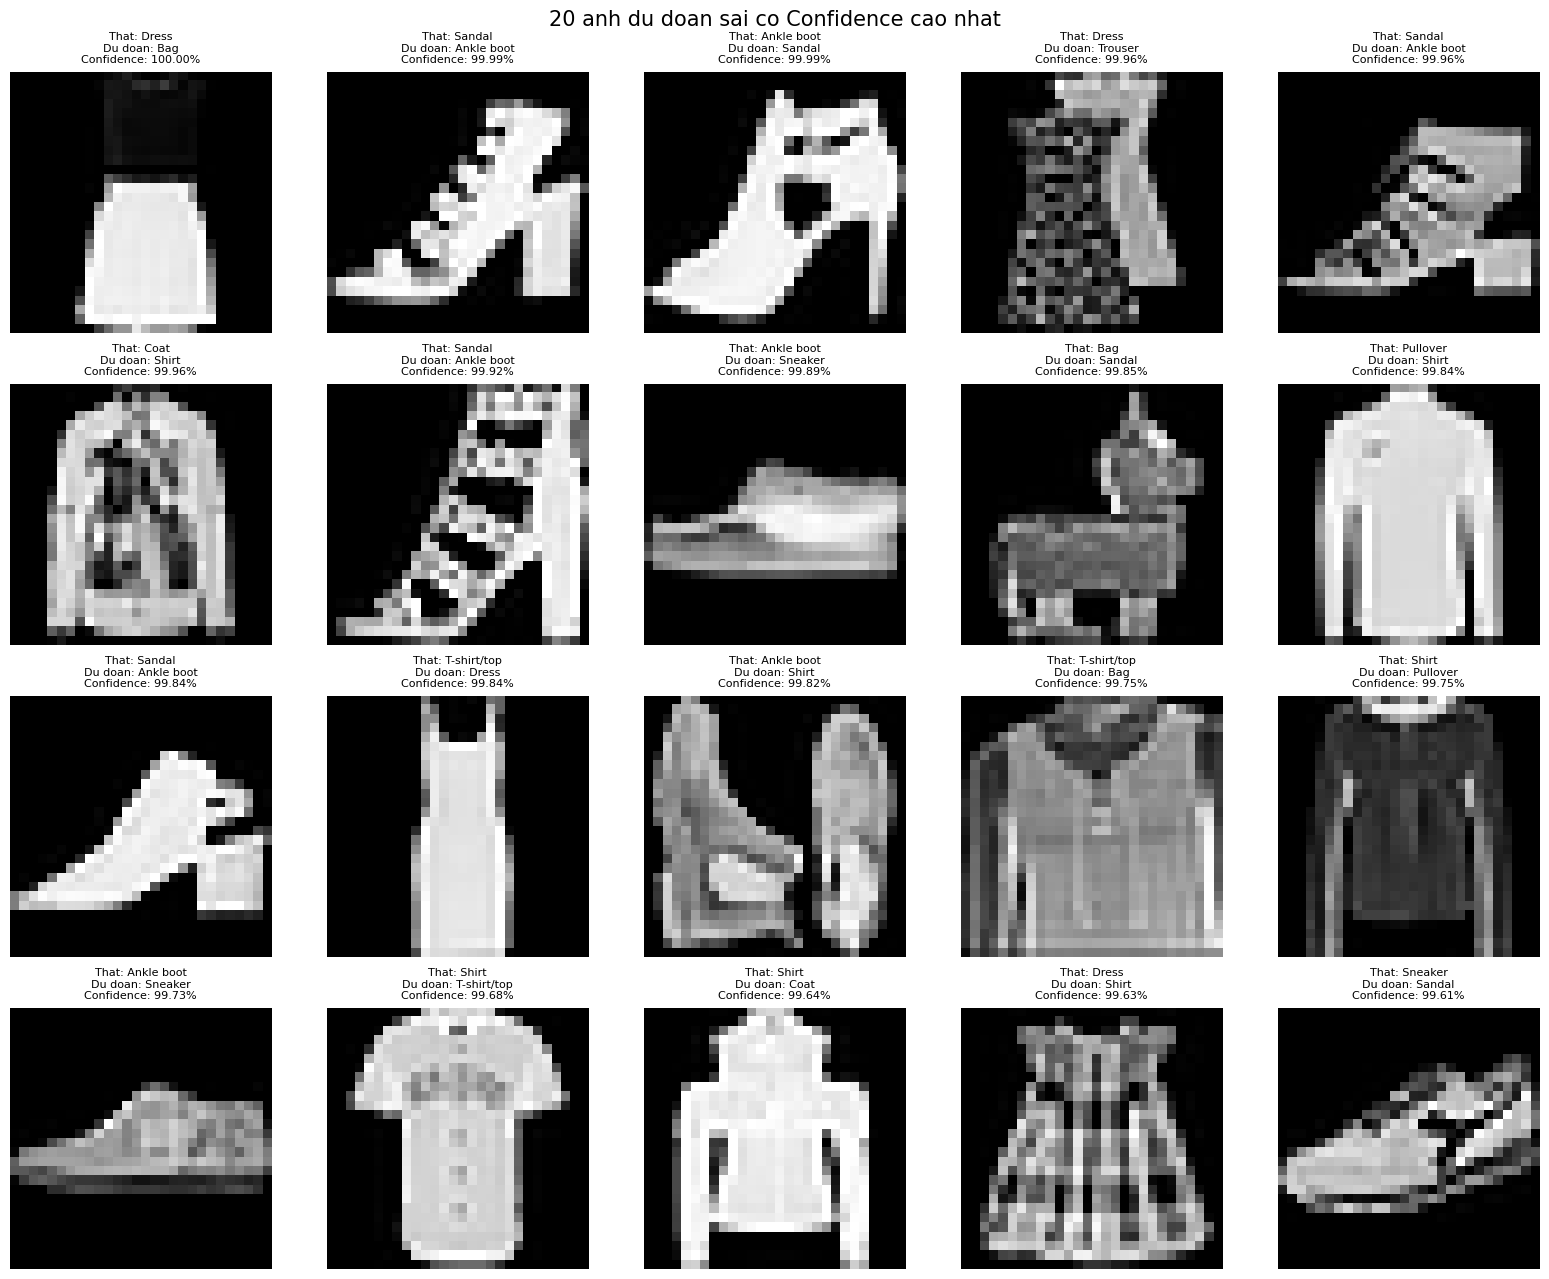

In [276]:

fig, axes = plt.subplots(4, 5, figsize=(16, 13))

for position, ax in enumerate(axes.flat):

    idx = top20_indices[position]

    image = X_test[idx].reshape(28, 28)

    ax.imshow(image, cmap="gray")

    ax.set_title(
        f"That: {class_names[y_true[idx]]}\n"
        f"Du doan: {class_names[y_pred[idx]]}\n"
        f"Confidence: {confidence[idx]*100:.2f}%",
        fontsize=8
    )

    ax.axis("off")

plt.suptitle(
    "20 anh du doan sai co Confidence cao nhat",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [277]:

# Tao confusion matrix
confusion = np.zeros((10, 10), dtype=int)

np.add.at(
    confusion,
    (y_true, y_pred),
    1
)

# Thong ke cac cap nham lan hai chieu
pair_results = []

for i in range(10):
    for j in range(i + 1, 10):

        count = confusion[i, j] + confusion[j, i]

        pair_results.append({
            "Cap lop": f"{class_names[i]} - {class_names[j]}",
            "So lan nham": count,
            f"{class_names[i]} -> {class_names[j]}": confusion[i, j],
            f"{class_names[j]} -> {class_names[i]}": confusion[j, i]
        })

pair_df = pd.DataFrame(pair_results)

pair_df = pair_df.sort_values(
    by="So lan nham",
    ascending=False
).reset_index(drop=True)

print("10 CAP LOP BI NHAM LAN NHIEU NHAT")
display(pair_df.head(10))

print("\nHAI CAP LOP BI NHAM LAN NHIEU NHAT")
display(pair_df.head(2))


10 CAP LOP BI NHAM LAN NHIEU NHAT


,Cap lop,So lan nham,T-shirt/top -> Trouser,Trouser -> T-shirt/top,T-shirt/top -> Pullover,Pullover -> T-shirt/top,T-shirt/top -> Dress,Dress -> T-shirt/top,T-shirt/top -> Coat,Coat -> T-shirt/top,...,Shirt -> Bag,Bag -> Shirt,Shirt -> Ankle boot,Ankle boot -> Shirt,Sneaker -> Bag,Bag -> Sneaker,Sneaker -> Ankle boot,Ankle boot -> Sneaker,Bag -> Ankle boot,Ankle boot -> Bag
0,T-shirt/top - Shirt,243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Pullover - Coat,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Pullover - Shirt,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Coat - Shirt,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Sneaker - Ankle boot,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,17.0,50.0,NaN,NaN
5,Dress - Shirt,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Dress - Coat,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Sandal - Sneaker,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,T-shirt/top - Dress,42,NaN,NaN,NaN,NaN,23.0,19.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Trouser - Dress,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



HAI CAP LOP BI NHAM LAN NHIEU NHAT


,Cap lop,So lan nham,T-shirt/top -> Trouser,Trouser -> T-shirt/top,T-shirt/top -> Pullover,Pullover -> T-shirt/top,T-shirt/top -> Dress,Dress -> T-shirt/top,T-shirt/top -> Coat,Coat -> T-shirt/top,...,Shirt -> Bag,Bag -> Shirt,Shirt -> Ankle boot,Ankle boot -> Shirt,Sneaker -> Bag,Bag -> Sneaker,Sneaker -> Ankle boot,Ankle boot -> Sneaker,Bag -> Ankle boot,Ankle boot -> Bag
0,T-shirt/top - Shirt,243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Pullover - Coat,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
